# ML Assignment 2 – Rain Prediction in Australia

Binary classification of `RainTomorrow` (Yes/No) on the **weatherAUS** dataset using 5 models:
Logistic Regression, Decision Tree, kNN, Naive Bayes (Gaussian) and Random Forest (Ensemble).

This notebook runs the pipeline step by step, using the functions defined in `train_models.py`.

## 0. Setup

In [3]:
# Install dependencies
%pip install -q -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [4]:
import os
import sys
import time

import joblib
import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

# Locate the project folder whether the notebook is started from the project root or from model/
PROJECT_DIR = os.path.abspath("..") if os.path.basename(os.getcwd()) == "model" else os.getcwd()
sys.path.insert(0, os.path.join(PROJECT_DIR, "model"))

import train_models as tm

os.makedirs(tm.MODEL_DIR, exist_ok=True)
os.makedirs(tm.PLOT_DIR, exist_ok=True)


def show_plot(name):
    display(Image(os.path.join(tm.PLOT_DIR, f"{name}.png")))


print("Project folder:", PROJECT_DIR)
print("Random seed   :", tm.RANDOM_SEED)

Project folder: /home/s2026ct05051/Downloads/202605051Proj
Random seed   : 27


## 1. Load the dataset and explore it
Shape, feature types, missing values and the class distribution of the target.

In [6]:
raw = tm.load_and_explore(tm.DATA_PATH)
raw.head()

STEP 1: DATASET OVERVIEW
Shape: 145460 rows x 23 columns

Column types:
Date              object
Location          object
MinTemp          float64
MaxTemp          float64
Rainfall         float64
Evaporation      float64
Sunshine         float64
WindGustDir       object
WindGustSpeed    float64
WindDir9am        object
WindDir3pm        object
WindSpeed9am     float64
WindSpeed3pm     float64
Humidity9am      float64
Humidity3pm      float64
Pressure9am      float64
Pressure3pm      float64
Cloud9am         float64
Cloud3pm         float64
Temp9am          float64
Temp3pm          float64
RainToday         object
RainTomorrow      object

Missing values per column:
               missing  percent
Sunshine         69835    48.01
Evaporation      62790    43.17
Cloud3pm         59358    40.81
Cloud9am         55888    38.42
Pressure9am      15065    10.36
Pressure3pm      15028    10.33
WindDir9am       10566     7.26
WindGustDir      10326     7.10
WindGustSpeed    10263     7.06
Humid

,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,WindDir9am,...,Humidity9am,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow
0,2008-12-01,Albury,13.4,22.9,0.6,NaN,NaN,W,44.0,W,...,71.0,22.0,1007.7,1007.1,8.0,NaN,16.9,21.8,No,No
1,2008-12-02,Albury,7.4,25.1,0.0,NaN,NaN,WNW,44.0,NNW,...,44.0,25.0,1010.6,1007.8,NaN,NaN,17.2,24.3,No,No
2,2008-12-03,Albury,12.9,25.7,0.0,NaN,NaN,WSW,46.0,W,...,38.0,30.0,1007.6,1008.7,NaN,2.0,21.0,23.2,No,No
3,2008-12-04,Albury,9.2,28.0,0.0,NaN,NaN,NE,24.0,SE,...,45.0,16.0,1017.6,1012.8,NaN,NaN,18.1,26.5,No,No
4,2008-12-05,Albury,17.5,32.3,1.0,NaN,NaN,W,41.0,ENE,...,82.0,33.0,1010.8,1006.0,7.0,8.0,17.8,29.7,No,No


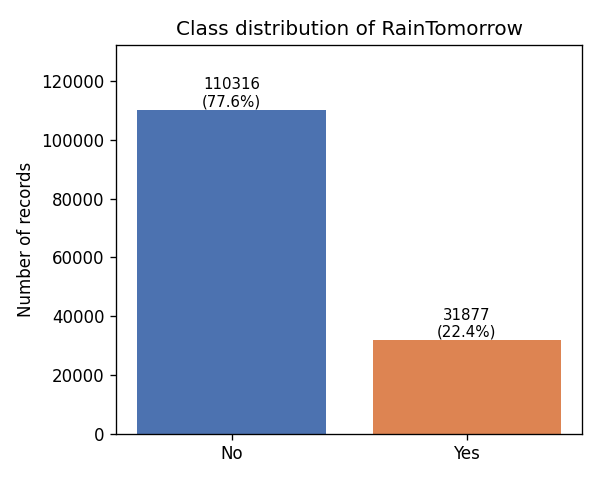

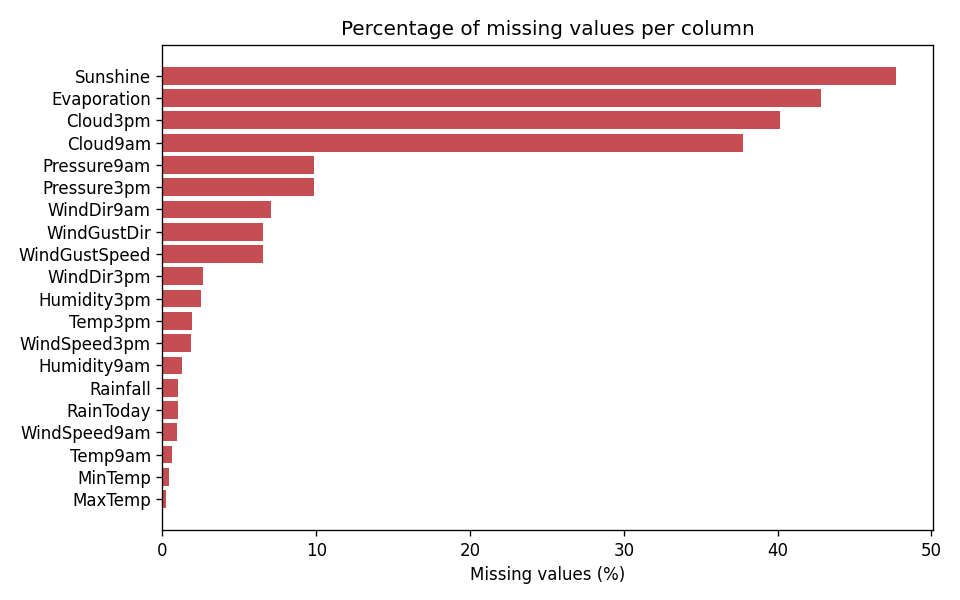

In [7]:
tm.plot_eda(raw.dropna(subset=[tm.TARGET]))
show_plot("class_distribution")
show_plot("missing_values")

## 2. Data preprocessing
- Drop rows with a missing target, then check for and remove duplicates
- Extract `Month` from `Date`
- Stratified 80:20 train-test split with a fixed seed
- Imputation, one-hot encoding and scaling happen **inside a Pipeline**, so they are fitted on the training data only

In [9]:
df = tm.clean_data(raw)

X = df.drop(columns=[tm.TARGET])
y = df[tm.TARGET]
numeric_cols = [c for c in X.columns if c not in tm.CATEGORICAL_COLS]
print(f"\nNumeric features ({len(numeric_cols)}):", numeric_cols)
print(f"Categorical features ({len(tm.CATEGORICAL_COLS)}):", tm.CATEGORICAL_COLS)


STEP 2: DATA CLEANING
Dropped 3267 rows with missing target -> 142193 rows
Duplicate rows found and removed: 0
Extracted 'Month' from 'Date' and dropped 'Date'

Numeric features (16): ['MinTemp', 'MaxTemp', 'Rainfall', 'Evaporation', 'Sunshine', 'WindGustSpeed', 'WindSpeed9am', 'WindSpeed3pm', 'Humidity9am', 'Humidity3pm', 'Pressure9am', 'Pressure3pm', 'Cloud9am', 'Cloud3pm', 'Temp9am', 'Temp3pm']
Categorical features (6): ['Location', 'WindGustDir', 'WindDir9am', 'WindDir3pm', 'RainToday', 'Month']


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=tm.TEST_SIZE, stratify=y, random_state=tm.RANDOM_SEED)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class ratio:", y_train.value_counts(normalize=True).round(4).to_dict())
print("Test  class ratio:", y_test.value_counts(normalize=True).round(4).to_dict())

# Save the raw test split as test_data.csv
test_out = X_test.copy()
test_out[tm.TARGET] = y_test
test_out.to_csv(tm.TEST_DATA_PATH, index=False)
print("Saved:", tm.TEST_DATA_PATH)

Train: (113754, 22)  Test: (28439, 22)
Train class ratio: {0: 0.7758, 1: 0.2242}
Test  class ratio: {0: 0.7758, 1: 0.2242}
Saved: /home/s2026ct05051/Downloads/202605051Proj/test_data.csv


## 3. Train the 5 models and evaluate them
Metrics: Accuracy, AUC, Precision, Recall, F1 and MCC. The positive class is Rain = Yes (1).

In [12]:
results, fitted = {}, {}

for name, (clf, scale) in tm.get_models().items():
    pipe = Pipeline([
        ("preprocess", tm.build_preprocessor(numeric_cols, tm.CATEGORICAL_COLS, scale)),
        ("classifier", clf),
    ])
    start = time.time()
    pipe.fit(X_train, y_train)
    y_proba = pipe.predict_proba(X_test)[:, 1]
    y_pred = (y_proba >= 0.5).astype(int)
    results[name] = tm.evaluate(y_test, y_pred, y_proba)
    fitted[name] = pipe
    print(f"{name:<26} trained in {time.time() - start:5.1f}s")

    file_name = name.lower().replace(" ", "_").replace("(", "").replace(")", "") + ".joblib"
    joblib.dump(pipe, os.path.join(tm.MODEL_DIR, file_name), compress=3)

Logistic Regression        trained in   5.8s
Decision Tree              trained in   3.7s
kNN                        trained in  37.1s
Naive Bayes                trained in   1.2s
Random Forest (Ensemble)   trained in  18.5s


### Comparison table

In [14]:
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = "ML Model Name"
results_df.to_csv(os.path.join(tm.RESULTS_DIR, "metrics_comparison.csv"))

print("Best model by MCC:", results_df["MCC"].idxmax())
print("Best model by AUC:", results_df["AUC"].idxmax())
results_df

Best model by MCC: Random Forest (Ensemble)
Best model by AUC: Random Forest (Ensemble)


,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.8463,0.8680,0.7263,0.5045,0.5954,0.5171
Decision Tree,0.8385,0.8479,0.6919,0.5040,0.5832,0.4954
kNN,0.8449,0.8639,0.7542,0.4573,0.5693,0.5041
Naive Bayes,0.6524,0.7441,0.3604,0.7106,0.4783,0.2907
Random Forest (Ensemble),0.8507,0.8788,0.7819,0.4629,0.5815,0.5232


## 4. Visualising the metrics

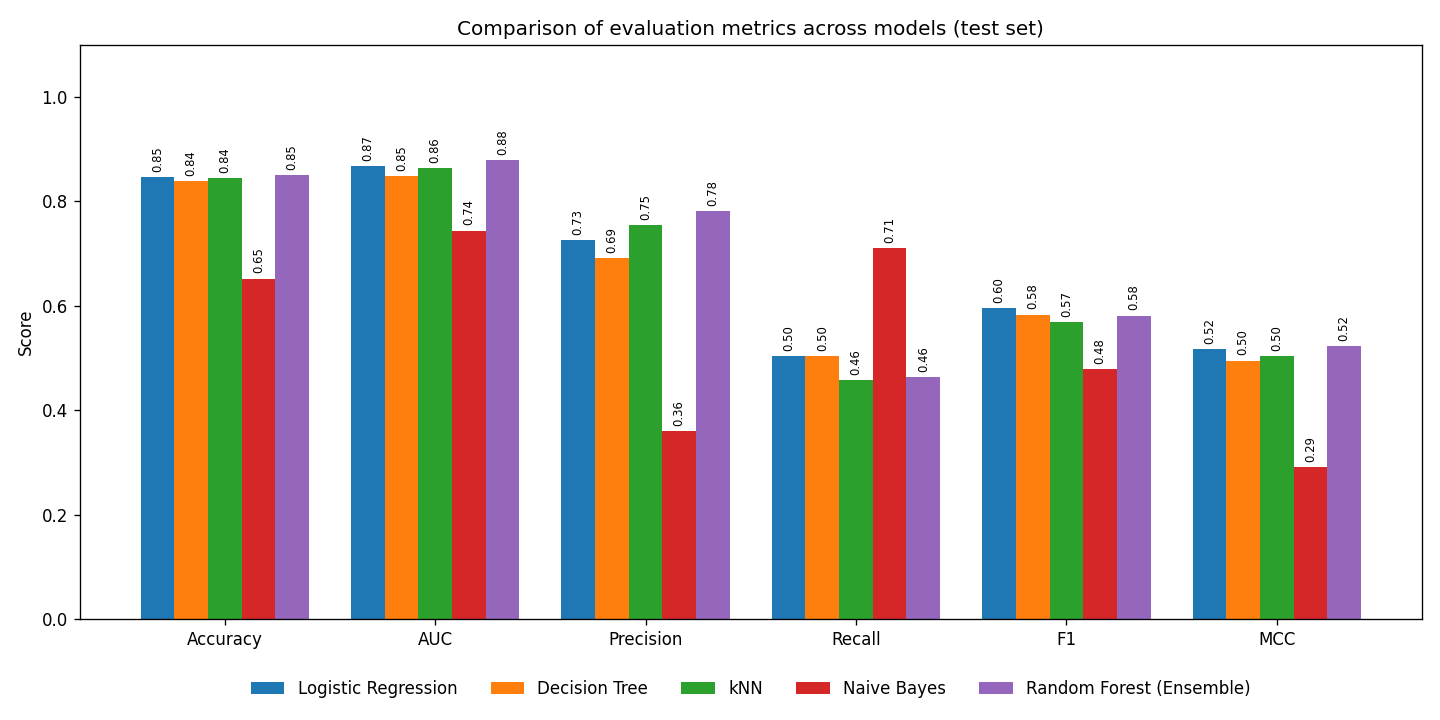

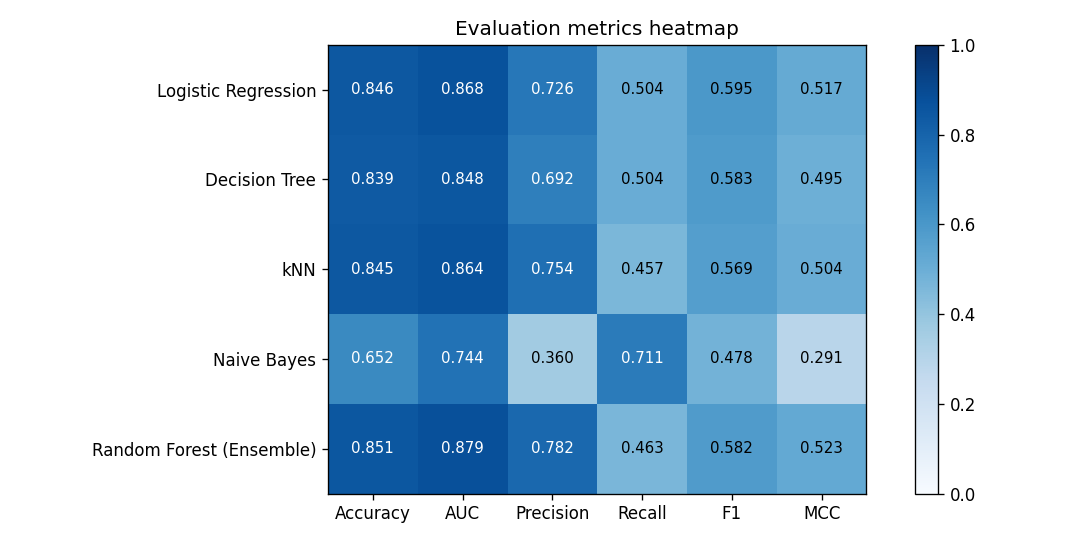

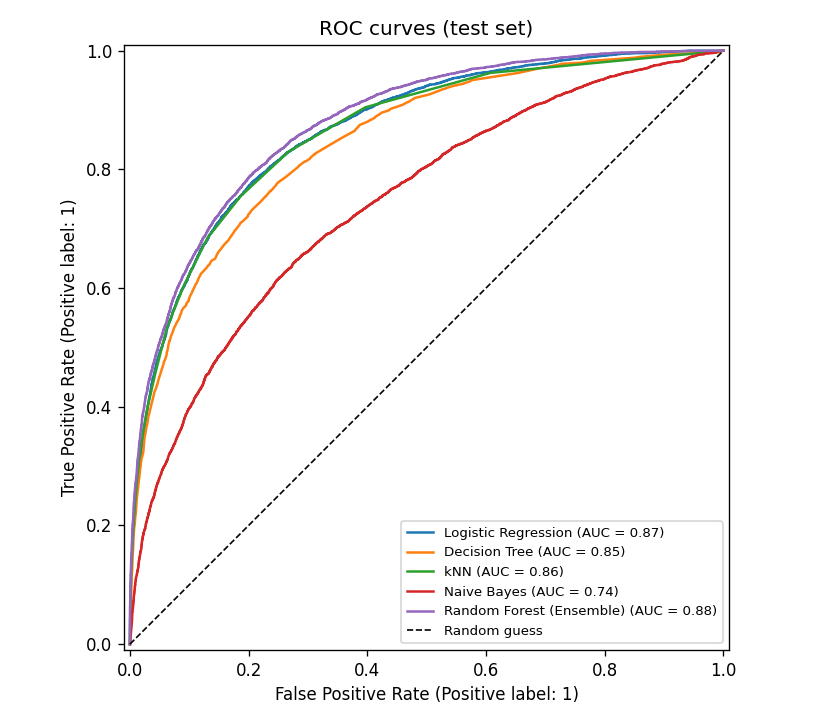

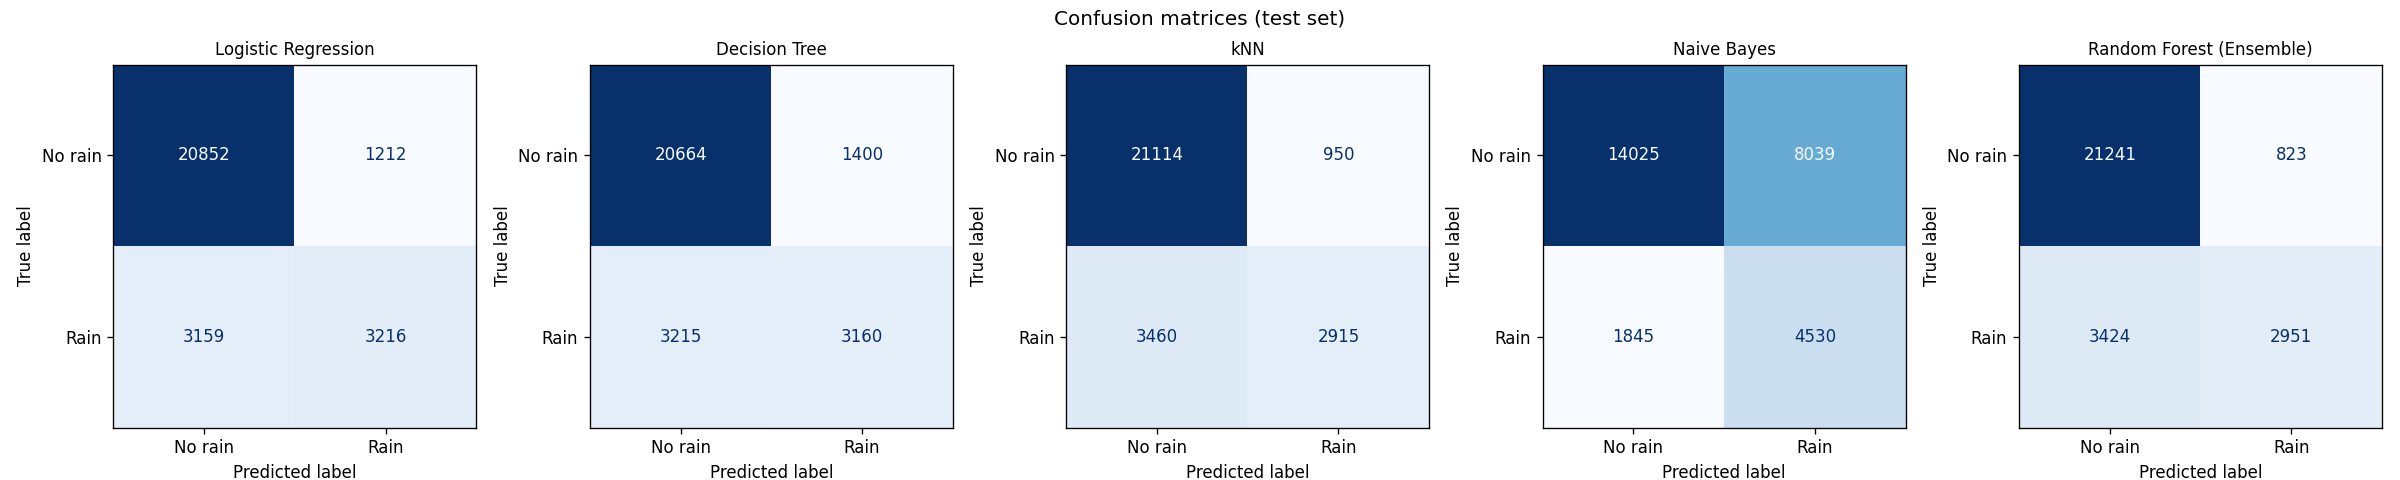

In [16]:
tm.plot_metric_comparison(results_df)
tm.plot_roc_and_confusion(fitted, X_test, y_test)

for name in ["metrics_comparison_bar", "metrics_heatmap", "roc_curves", "confusion_matrices"]:
    show_plot(name)

## 5. Observations
*Every model's recall for the rain class is clearly lower than its accuracy. This is an effect of the 77.6/22.4 class imbalance: accuracy looks high mainly because "No rain" is easy to predict.
MCC separates the models much more clearly than accuracy does (0.29–0.52 vs 0.65–0.85), which shows why MCC is a better metric for imbalanced data.*